In [25]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [26]:
os.environ['GROQ_API_KEY']=os.getenv('GROQ_API_KEY')

In [27]:


from langchain.chat_models import init_chat_model
llm1= init_chat_model(model="openai/gpt-oss-120b",model_provider='groq')
llm2= init_chat_model(model="qwen-2.5-32b",model_provider='groq')

In [28]:
from langchain.messages import AIMessage, HumanMessage,SystemMessage,ToolMessage
from pprint import pprint

In [29]:
msgs= [AIMessage(content='These concepts form the foundation for building more complex LangGraph applications—anything from multi‑step assistants to dynamic data pipelines.',name='LLM Model')]
msgs.append(HumanMessage(content='I  want to learn langgraph', name='krish'))
msgs.append(AIMessage('TELL me how i can help you ', name='LLM Model'))


In [30]:
for msg in msgs:
    msg.pretty_print()

================================== Ai Message ==================================
Name: LLM Model

These concepts form the foundation for building more complex LangGraph applications—anything from multi‑step assistants to dynamic data pipelines.
================================ Human Message =================================
Name: krish

I  want to learn langgraph
================================== Ai Message ==================================
Name: LLM Model

TELL me how i can help you


In [31]:
llm1.invoke(msgs).pretty_print()

================================== Ai Message ==================================

Absolutely—let’s get you started with **LangGraph**, the framework that lets you build powerful, multi‑step, state‑driven applications on top of LLMs (and other tools). Below is a structured roadmap you can follow, plus resources, code snippets, and tips to keep you moving forward.

---

## 1️⃣ What Is LangGraph? (High‑Level Overview)

| Concept | What It Means | Why It Matters |
|---------|---------------|----------------|
| **Graph‑based workflow** | Your app is a directed graph of **nodes** (functions/agents) and **edges** (transitions). | Makes complex reasoning, branching, loops, and retries explicit and testable. |
| **State store** | A mutable `dict` (or any serializable object) that travels with the graph. | Lets every node read/write shared context—perfect for multi‑turn conversations, tool usage, or data pipelines. |
| **Node** | A Python callable (sync or async) that receives `state` and return

In [32]:
llm1.invoke(msgs).content

'## 🎓 Getting Started with LangGraph\n\nLangGraph is a **graph‑oriented** extension of the LangChain ecosystem that lets you compose LLM‑driven workflows as nodes and edges. Think of it as a way to turn a “conversation” or “data pipeline” into a **visual, modular graph** where each step can be a prompt, a tool call, a conditional branch, a loop, or anything you can code.\n\nBelow is a **step‑by‑step learning roadmap**, plus a quick‑start example you can run today.\n\n---\n\n## 1️⃣ Prerequisites (What to Know First)\n\n| Skill | Why It Matters | Quick Resources |\n|-------|----------------|-----------------|\n| **Python 3.9+** | LangGraph is a Python library. | Official tutorial: <https://docs.python.org/3/tutorial/> |\n| **Async/Await** | Most LangGraph runtimes are asynchronous. | Real‑Python async guide: <https://realpython.com/async-io-python/> |\n| **Basic LangChain** | LangGraph builds on LangChain concepts (LLM wrappers, prompts, tools). | LangChain docs: <https://python.langchai

In [33]:
from langchain.tools import  tool

In [34]:
# router 
# Question: What is the difference between Router and Edge in LangGraph?

# Answer:

#  An Edge defines the connection between two nodes in a LangGraph workflow, 
#  whereas a Router is a decision-making function that determines
#  which node should execute next based on the current state. 
#  In LangGraph, conditional edges use router functions to implement dynamic routing."

# Remember this simple concept:
# - Router = Decision maker
# - Edge = Connection
# - Conditional Edge = Connection based on decision

In [35]:

def add(a:int, b:int)->int:
    """ add a and b 
    Args:
        a(int):_description_
        b(int):_description_
    
    Returns:
        int:_description_
        
        """
    return a+b
@tool
def subtract(a:int, b:int)->int:
    """ subtract a and b 
    Args:
        a(int):_description_
        b(int):_description_
    
    Returns:
        int:_description_
        
        """
    return a-b
    

In [36]:
llm1

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.4', 'langchain': '1.4.2'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000281881D7390>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000028188280050>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [37]:
# Model ko force karega koi na koi tool call karne ke liye
llm_with_tool = llm1.bind_tools([add])

# Ya specific tool name force karne ke liye:
# llm_with_tool = llm.bind_tools([add_tool], tool_choice="add")

llm_with_tool.invoke([HumanMessage(content=f'what is 2 plus 2', name='mohit')])

AIMessage(content='2\u202f+\u202f2\u202f=\u202f4.', additional_kwargs={'reasoning_content': 'User asks "what is 2 plus 2". Simple addition. Could answer directly: 4. No need to call function.'}, response_metadata={'token_usage': {'completion_tokens': 47, 'prompt_tokens': 146, 'total_tokens': 193, 'completion_time': 0.099222991, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.007970992, 'prompt_tokens_details': None, 'queue_time': 0.244982981, 'total_time': 0.107193983}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_60e4b492db', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e4a9-fa5e-7123-afc6-535500d303bf-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 146, 'output_tokens': 47, 'total_tokens': 193, 'output_token_details': {'reasoning': 28}})

In [38]:
tool_call=llm_with_tool.invoke([HumanMessage(content=f'what is 2 plus 2', name='mohit')])
tool_call.tool_calls

[]

In [39]:
#massages as state
from langchain.messages import AnyMessage
from typing_extensions import TypedDict

class State(TypedDict):
    message:list[AnyMessage]

In [40]:
#massages as state
from langchain.messages import AnyMessage
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages
class State(TypedDict):
    message:Annotated[list[AnyMessage], add_messages]
    name:str

In [41]:
# reducers add_messages is to append instead of override

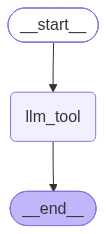

In [42]:
from openai.types.fine_tuning.alpha.grader_run_response import GraderRunResponse
from langgraph.graph import StateGraph,START,END
# chatbot node functionality
def llm_tool(state:State):
    return {'messages':[llm_with_tool.invoke(state['message'])]}

graph= StateGraph(State)

graph.add_node('llm_tool', llm_tool)

graph.add_edge(START,'llm_tool')

graph.add_edge('llm_tool', END)

graph.compile()


In [43]:
graph.compile().invoke({'message':'what is 2 plus 2'})

{'message': [HumanMessage(content='what is 2 plus 2', additional_kwargs={}, response_metadata={}, id='ab9442ad-f6df-409a-8e29-ff6a576abcce')]}

In [44]:
from langgraph.prebuilt import tool_node, tools_condition,ToolNode
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

In [45]:
tool= [add]

In [46]:
from langgraph.prebuilt import ToolNode, tools_condition

tool = [add]

graph = StateGraph(State)

# 1. Nodes add karein (naam 'tools' rakha)
graph.add_node('llm_tool', llm_tool)
graph.add_node('tools', ToolNode(tool))

# 2. Edges connect karein
graph.add_edge(START, 'llm_tool')
graph.add_conditional_edges(
    'llm_tool',
    tools_condition
)
graph.add_edge('tools', 'llm_tool')

# 3. Compile graph
app = graph.compile()

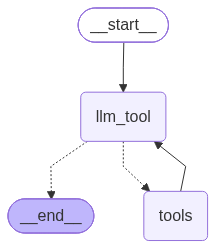

In [47]:
graph.compile()

In [48]:
response = app.invoke({"messages": [HumanMessage(content="what is 2 plus 2", name="mohit")]})

for msg in response["messages"]:
    msg.pretty_print()

BadRequestError: Error code: 400 - {'error': {'message': "'messages' : minimum number of items is 1", 'type': 'invalid_request_error'}}

In [49]:
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

In [ ]:
def llm_tool(state: State):
    msgs = state.get('messages', [])
    return {'messages': [llm_with_tool.invoke(msgs)]}

tool = [add]
app = graph.compile()
response = app.invoke({"messages": [HumanMessage(content="what is 2 plus 2", name="mohit")]})

for msg in response["messages"]:
    msg.pretty_print()
    

BadRequestError: Error code: 400 - {'error': {'message': "'messages' : minimum number of items is 1", 'type': 'invalid_request_error'}}